In [1]:
import torch
import torchvision
import os
import random
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Seed para replicar o modelo
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

In [2]:
# Transformações para normalização e aumento de dados (caso necessário)
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Carregando o dataset completo
full_data = datasets.ImageFolder(r"C:\Users\danie\OneDrive\Desktop\ResNetWavelet", transform=transform)

# Dividindo o dataset em treinamento, validação e teste
def split_dataset(dataset, train_size=0.6, val_size=0.2, test_size=0.2):
    assert train_size + val_size + test_size == 1.0, "A soma dos tamanhos de treino, validação e teste deve ser 1.0"
    
    # Dividindo o dataset em treino e teste
    train_indices, test_indices = train_test_split(range(len(dataset)), test_size=test_size, random_state=42, stratify=dataset.targets)
    
    # Dividindo o conjunto de treino em treino e validação
    train_indices, val_indices = train_test_split(train_indices, test_size=val_size / (train_size + val_size), random_state=42, stratify=np.array(dataset.targets)[train_indices])
    
    # Criando subsets para treino, validação e teste
    train_subset = torch.utils.data.Subset(dataset, train_indices)
    val_subset = torch.utils.data.Subset(dataset, val_indices)
    test_subset = torch.utils.data.Subset(dataset, test_indices)
    
    return train_subset, val_subset, test_subset

# Dividindo o dataset
train_data, val_data, test_data = split_dataset(full_data, train_size=0.6, val_size=0.2, test_size=0.2)

# Criando dataloaders para iterar sobre os dados durante o treinamento
train_loader = torch.utils.data.DataLoader(train_data, batch_size=32, shuffle=False)
val_loader = torch.utils.data.DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=1, shuffle=False)

# Definindo as classes do dataset
classes = full_data.classes

In [3]:
# Carregando o modelo ResNet-50 pré-treinado ou não (mudar True para False)
model = models.resnet50(pretrained=False)

# Congelando os parâmetros das camadas existentes
for param in model.parameters():
    param.requires_grad = False

# Substituindo a camada final para classificação multiclasse
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(classes))

# Definindo a função de perda e otimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

C:\Users\danie\anaconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\danie\anaconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [4]:
# Utilização da GPU se for possível
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
# Caminhos para salvar os pesos e o modelo
save_weights = r'C:\Users\danie\OneDrive\Desktop\ResNetArtigo2'
save_model = r'C:\Users\danie\OneDrive\Desktop\ResNetModelos\ResNetWavelet100.pt'

In [6]:
model.to(device)
num_epochs = 400

# Listas para armazenar perda e acurácia
train_loss_values = []
val_loss_values = []
train_accuracy_values = []
val_accuracy_values = []

# Treinamento e coleta de dados
best_accuracy = 0.0

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
            
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
            
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        
    epoch_loss = running_loss / len(train_loader.dataset)
    train_accuracy = correct / total

    train_loss_values.append(epoch_loss)
    train_accuracy_values.append(train_accuracy)

    # Validação
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader.dataset)
    val_accuracy = val_correct / val_total

    val_loss_values.append(val_loss)
    val_accuracy_values.append(val_accuracy)
    
    # Print da loss e accuracy para cada época
    print(f'Epoch {epoch+1}/{num_epochs}, '
          f'Training Loss: {epoch_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
          f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}')
    
    # Salvamento dos pesos
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        model_save_path = os.path.join(save_weights, f'model_epoch_{epoch+1}_val_accuracy_{val_accuracy:.4f}.pt')
        torch.save(model.state_dict(), model_save_path)
        print(f'Saved best weighs at epoch {epoch+1} with validation accuracy: {val_accuracy:.4f}')
        
print('Treinamento finalizado')

# Salvar o modelo inteiro
torch.save(model, save_model)
print(f'Saved entire model at {save_model}')

Epoch 1/100, Training Loss: 1.0008, Training Accuracy: 0.6158, Validation Loss: 0.6939, Validation Accuracy: 0.7684
Saved best weighs at epoch 1 with validation accuracy: 0.7684
Epoch 2/100, Training Loss: 0.6536, Training Accuracy: 0.7719, Validation Loss: 0.5510, Validation Accuracy: 0.8092
Saved best weighs at epoch 2 with validation accuracy: 0.8092
Epoch 3/100, Training Loss: 0.5408, Training Accuracy: 0.8121, Validation Loss: 0.4858, Validation Accuracy: 0.8184
Saved best weighs at epoch 3 with validation accuracy: 0.8184
Epoch 4/100, Training Loss: 0.4755, Training Accuracy: 0.8351, Validation Loss: 0.4433, Validation Accuracy: 0.8401
Saved best weighs at epoch 4 with validation accuracy: 0.8401
Epoch 5/100, Training Loss: 0.4299, Training Accuracy: 0.8548, Validation Loss: 0.4108, Validation Accuracy: 0.8539
Saved best weighs at epoch 5 with validation accuracy: 0.8539
Epoch 6/100, Training Loss: 0.3949, Training Accuracy: 0.8708, Validation Loss: 0.3845, Validation Accuracy: 0

Epoch 54/100, Training Loss: 0.0808, Training Accuracy: 0.9890, Validation Loss: 0.1611, Validation Accuracy: 0.9493
Epoch 55/100, Training Loss: 0.0790, Training Accuracy: 0.9901, Validation Loss: 0.1611, Validation Accuracy: 0.9493
Epoch 56/100, Training Loss: 0.0773, Training Accuracy: 0.9901, Validation Loss: 0.1612, Validation Accuracy: 0.9500
Epoch 57/100, Training Loss: 0.0757, Training Accuracy: 0.9917, Validation Loss: 0.1615, Validation Accuracy: 0.9500
Epoch 58/100, Training Loss: 0.0741, Training Accuracy: 0.9919, Validation Loss: 0.1618, Validation Accuracy: 0.9500
Epoch 59/100, Training Loss: 0.0725, Training Accuracy: 0.9921, Validation Loss: 0.1622, Validation Accuracy: 0.9500
Epoch 60/100, Training Loss: 0.0710, Training Accuracy: 0.9921, Validation Loss: 0.1626, Validation Accuracy: 0.9500
Epoch 61/100, Training Loss: 0.0695, Training Accuracy: 0.9930, Validation Loss: 0.1632, Validation Accuracy: 0.9493
Epoch 62/100, Training Loss: 0.0681, Training Accuracy: 0.9932, 

In [7]:
# Carregamento do modelo
model = torch.load(save_model)
model.eval()
print(f'Loaded model from {save_model}')

# Carregamento dos pesos
# pesos = r'C:\Users\danie\OneDrive\Desktop\ResNetPesos\model_epoch_3_val_accuracy_0.8539.pt'
model.load_state_dict(torch.load(model_save_path))
model.eval()
print(f'Loaded weights from {model_save_path}')

Loaded model from C:\Users\danie\OneDrive\Desktop\ResNetModelos\ResNetWavelet100.pt
Loaded weights from C:\Users\danie\OneDrive\Desktop\ResNetArtigo2\model_epoch_52_val_accuracy_0.9507.pt


In [8]:
# Confirmação do carregamento do modelo e dos pesos
model.to(device)

model.eval()
confirmation_correct = 0
confirmation_total = 0
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        confirmation_total += labels.size(0)
        confirmation_correct += (predicted == labels).sum().item()
        
print(f'Confirmation Accuracy: { confirmation_correct / confirmation_total:.4f}')


Confirmation Accuracy: 0.9507


In [9]:
# Teste do modelo utilizando a base de teste para curva ROC e matriz de confusão
model.eval()

all_labels = []
all_preds = []

with torch.no_grad():
   for inputs, labels in test_loader:
       inputs, labels = inputs.to(device), labels.to(device)
       outputs = model(inputs)
       probs = torch.nn.functional.softmax(outputs, dim=1)
       all_labels.append(labels.cpu().numpy())
       all_preds.append(probs.cpu().numpy())

all_labels = np.concatenate(all_labels)
all_preds = np.concatenate(all_preds)

binarized_labels = label_binarize(all_labels, classes=range(len(classes)))

fpr = {}
tpr = {}
roc_auc = {}

for i in range(len(classes)):
    fpr[i], tpr[i], _ = roc_curve(binarized_labels[:, i], all_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])     


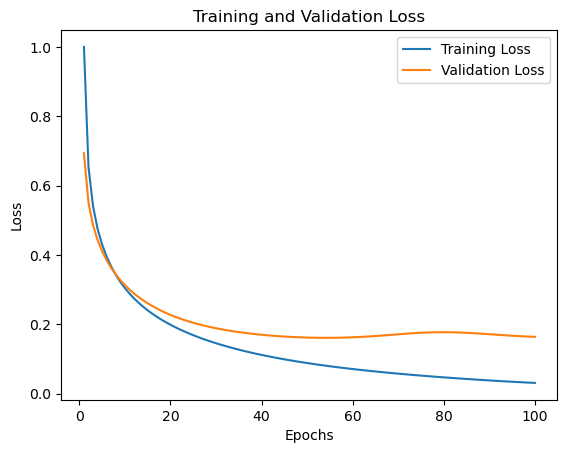

In [10]:
# Plotando a perda
epochs = range(1, num_epochs + 1)

plt.figure()
plt.plot(epochs, train_loss_values, label='Training Loss')
plt.plot(epochs, val_loss_values, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()


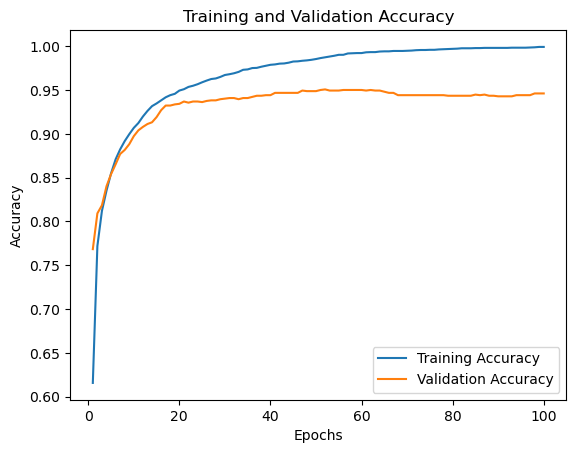

In [11]:
# Plotando a acurácia
plt.figure()
plt.plot(epochs, train_accuracy_values, label='Training Accuracy')
plt.plot(epochs, val_accuracy_values, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

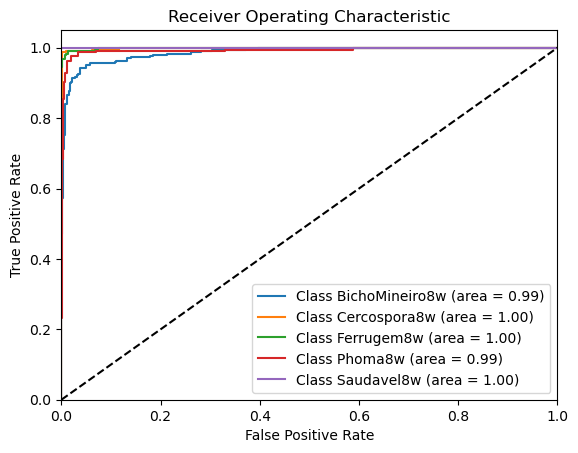

In [12]:
# Plotando todas as curvas ROC
plt.figure()
for i in range(len(classes)):
    plt.plot(fpr[i], tpr[i], label=f'Class {classes[i]} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc='lower right')
plt.show()


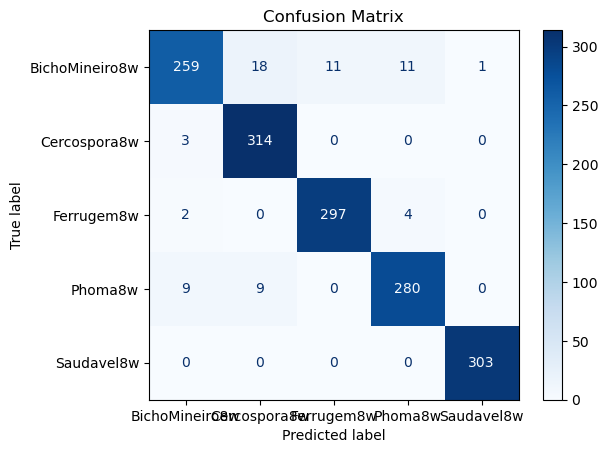

In [13]:
# Calculando a matriz de confusão
test_preds = np.argmax(all_preds, axis=1)
cm = confusion_matrix(all_labels, test_preds)

# Plotando a matriz de confusão
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

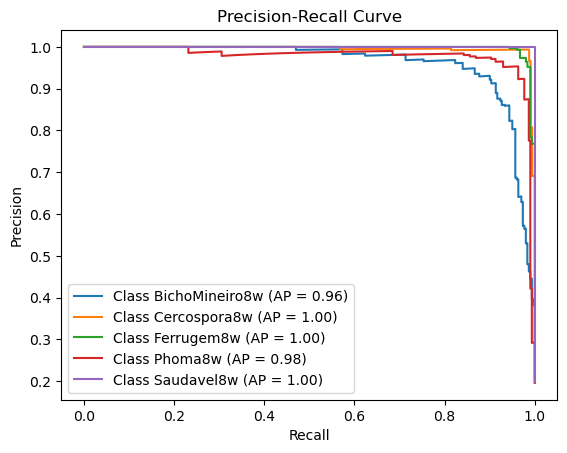

In [14]:
# Calculando a curva Precision-Recall e Average Precision
precision = {}
recall = {}
average_precision = {}

for i in range(len(classes)):
    precision[i], recall[i], _ = precision_recall_curve(binarized_labels[:, i], all_preds[:, i])
    average_precision[i] = average_precision_score(binarized_labels[:, i], all_preds[:, i])

# Plotando todas as curvas Precision-Recall
plt.figure()
for i in range(len(classes)):
    plt.plot(recall[i], precision[i], label=f'Class {classes[i]} (AP = {average_precision[i]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.show()